#Question 2 – Cross-Validation and Bias-Variance

## Task a

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df2 = pd.read_csv("/content/HW2_q2_data.csv")    # columns: x2, y2
x2 = df2["x2"].to_numpy()
y2 = df2["y2"].to_numpy()
N2 = len(y2)

print("N =", N2)
df2.head()

N = 60


,x2,y2
0,-3.000000,-28.527748
1,-2.898305,-28.027028
2,-2.796610,-26.405617
3,-2.694915,-20.171026
4,-2.593220,-16.669239


In [4]:
degrees = [1, 3, 9]
colors = {1: "tab:red", 3: "tab:green", 9: "tab:purple"}

def fit(xt, yt, d):
    return np.polyfit(xt, yt, d)       # least squares polynomial fit

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

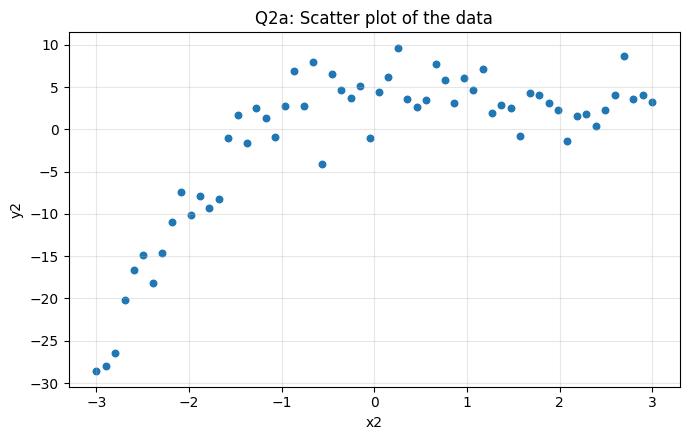

In [5]:
plt.figure(figsize=(7, 4.5))
plt.scatter(x2, y2, s=22, color="tab:blue")
plt.xlabel("x2"); plt.ylabel("y2")
plt.title("Q2a: Scatter plot of the data")
plt.grid(alpha=.3); plt.tight_layout()
plt.show()

## Task b

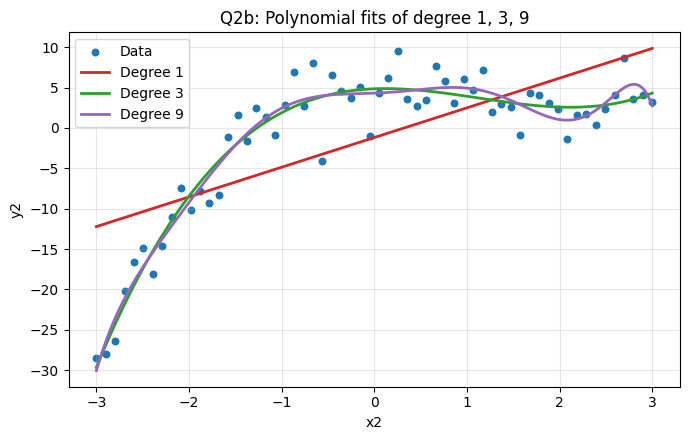

In [6]:
xs = np.linspace(x2.min(), x2.max(), 500)

plt.figure(figsize=(7, 4.5))
plt.scatter(x2, y2, s=22, color="tab:blue", label="Data")
for d in degrees:
    p = fit(x2, y2, d)
    plt.plot(xs, np.polyval(p, xs), color=colors[d], lw=2, label=f"Degree {d}")
plt.xlabel("x2"); plt.ylabel("y2")
plt.title("Q2b: Polynomial fits of degree 1, 3, 9")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.show()

## Task c

In [7]:
rng = np.random.default_rng(0)
idx = rng.permutation(N2)
folds = np.array_split(idx, 5)

cv = {}
for d in degrees:
    errs = []
    for k in range(5):
        te = folds[k]
        tr = np.concatenate([folds[j] for j in range(5) if j != k])
        p = fit(x2[tr], y2[tr], d)
        errs.append(mse(y2[te], np.polyval(p, x2[te])))
    cv[d] = (np.mean(errs), errs)

print("=== Q2c: 5-fold CV ===")
for d in degrees:
    print(f"degree {d}: mean CV-MSE = {cv[d][0]:.4f}   folds = {np.round(cv[d][1], 3)}")

=== Q2c: 5-fold CV ===
degree 1: mean CV-MSE = 44.1650   folds = [41.295 53.074 67.111 32.459 26.886]
degree 3: mean CV-MSE = 7.0857   folds = [ 2.47   8.062  5.381  8.413 11.103]
degree 9: mean CV-MSE = 8.9740   folds = [ 3.392  8.259 12.805  9.618 10.797]


#Question 3 – Model Evaluation using AIC and BIC

In [8]:
res = {}
print("=== Q3 ===")
for d in degrees:
    p = fit(x2, y2, d)
    m = mse(y2, np.polyval(p, x2))
    k = d + 1
    aic = N2 * np.log(m) + 2 * k
    bic = N2 * np.log(m) + k * np.log(N2)
    res[d] = (m, k, aic, bic)
    print(f"degree {d}: k={k}  MSE={m:.4f}  AIC={aic:.3f}  BIC={bic:.3f}")

print("\nAIC best: degree", min(res, key=lambda d: res[d][2]))
print("BIC best: degree", min(res, key=lambda d: res[d][3]))
print("CV  best: degree", min(cv,  key=lambda d: cv[d][0]))

=== Q3 ===
degree 1: k=2  MSE=41.8154  AIC=227.996  BIC=232.185
degree 3: k=4  MSE=6.4601  AIC=119.939  BIC=128.316
degree 9: k=10  MSE=5.8695  AIC=126.186  BIC=147.130

AIC best: degree 3
BIC best: degree 3
CV  best: degree 3
